In [40]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [41]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [285]:
orf_distances = pl.read_csv(f'{outputs_dir}/orf_distances.csv', null_values=".", infer_schema_length=10000)
df = pl.read_csv(f'{outputs_dir}/edges_df.csv', null_values=".", infer_schema_length=10000)


In [286]:
# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,unique_id,manual_score_growth_updated,contamination,outlier_score,outlier_size_score,outlier_flag,size_score_raw,size_score,ad_symbol,symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,…,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
str,str,str,str,str,str,i64,bool,i64,str,i64,i64,str,str,str,str,f64,f64,i64,i64,i64,f64,bool,bool,bool,bool,f64,f64,str,str,str,str,str,str,f64,f64,str,…,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,bool,str,str,str,str,i64,i64,str,bool,f64,f64,f64,f64,f64,str
"""VUSAPWT1B2r03_027""","""K05""","""VUSAPWT1B2r03_025_026_027_028_…","""VUSAPWT1B2""","""r09""","""LWH1""",1,false,53886,null,6983,216124,"""VUSMutY8Dh029""","""C09""","""CEGSint_Y8A_3""","""H02""",530.573874,3.0,1061,1,98787,3.0,false,false,false,false,562938.880595,524.151658,"""AES""","""PITX2""","""Lys141Glu""","""PITX2_Lys141Glu""","""NC_000004.12:110618679:T:C""","""421A>G""",4.0,1.10618679e8,"""T""",…,null,null,null,null,null,null,null,null,null,null,null,null,98.17,61.463417,""">90""","""10-90""","""180500""","""autosomal dominant""","""OMIM""","""Rare genetic eye disease; Rare…",5.0,"""AXENFELD-RIEGER SYNDROME, TYPE…",false,"""6983.0_216124.0_VUSAPWT1B2""","""6983.0_216124.0_LWH1_VUSAPWT1B…","""53886.0_6983.0_216124.0_VUSAPW…","""53886.0_6983.0_VUSAPWT1B2""",1,1,"""Y""",false,487.580588,18.2474,3.0,400.13812,0.284497,"""PITX2_AES_Lys141Glu"""
"""VUSAPWT1B1r05_032""","""M11""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""",1,false,1611,null,2713,200824,"""VUSMutY8Dh018""","""H02""","""CEGSint_Y8A_6""","""D03""",477.227456,3.0,1121,1,298569,3.0,false,false,false,false,534971.978648,498.111712,"""SPERT""","""MLH1""","""Ser106Arg""","""MLH1_Ser106Arg""","""NC_000003.12:37004412:C:G""","""318C>G""",3.0,3.7004412e7,"""C""",…,"""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,91.46,0.7692308,""">90""","""<10""",null,null,null,"""Rare genetic immune disease; R…",3.0,null,false,"""2713.0_200824.0_VUSAPWT1B1""","""2713.0_200824.0_LWH25_VUSAPWT1…","""1611.0_2713.0_200824.0_VUSAPWT…","""1611.0_2713.0_VUSAPWT1B1""",1,1,"""Y""",false,401.266372,2.593389,3.0,395.512624,0.020784,"""MLH1_SPERT_Ser106Arg"""
"""VUSAPWT1B2r05_023""","""C03""","""VUSAPWT1B2r05_019_020_021_022_…","""VUSAPWT1B2""","""r11""","""LWH25""",1,false,244,null,1256,214008,"""VUSMutY8Dh028""","""F09""","""CEGSint_Y8A_1""","""G09""",471.864064,3.0,1028,1,127609,3.0,false,false,false,false,485076.257433,451.653871,"""KEAP1""","""KLHL3""","""Ala77Glu""","""KLHL3_Ala77Glu""","""NC_000005.10:137709761:G:T""","""230C>A""",5.0,1.37709761e8,"""G""",…,"""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,92.22,60.377357,""">90""","""10-90""","""145260""","""autosomal dominant""","""OMIM""","""Rare genetic renal disease""",1.0,"""PSEUDOHYPOALDOSTERONISM, TYPE …",false,"""1256.0_214008.0_VUSAPWT1B2""","""1256.0_214008.0_LWH25_VUSAPWT1…","""244.0_1256.0_214008.0_VUSAPWT1…","""244.0_1256.0_VUSAPWT

In [290]:
# keep only relevant columns for this notebook

# keep only relevant columns for this notebook
df[[
    'db_mut_id', 
    'symbol', 
    'ad_symbol', 
    'aa_change',
    'log2fc',
    'clinvar_clnsig_clean_pp_strict'
]].write_csv('./tmp/edges_df_luke.csv')

In [49]:
# Tables for Leo

# df.select(['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'ad_symbol', 'ad_orf_id', 'clinvar_clnsig_clean', 'consensus_score', 'wt_consensus_score', 'log2fc']).write_csv(f"{outputs_dir}/ppi_level_scores_minimal_Leo.csv")

# orf_distances[['symbol', 'db_orf_id', 'aa_change', 'db_mut_id', 'gene_variant' ,'clinvar_clnsig_clean', 'norm_dist_rms']].write_csv(f"{outputs_dir}/orf_distances_minimal_Leo.csv")

In [51]:
orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("norm_dist_rms").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "norm_dist_rms", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv")

orf_distances.with_columns(
    pl.col("norm_dist_rms").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv")

In [52]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
# Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Variants_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Variants_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Variants_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2026-01-06_20:25:52 INFO: Reading input 
2026-01-06_20:25:52 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2026-01-06_20:25:53 INFO: Drawing LLR plot 
2026-01-06_20:25:53 INFO: Drawing PRC curve 
  |======================================================================| 100%2026-01-06_20:25:54 INFO: Category transitions:  
0.547 : none -> patho.support
0.641 : patho.support -> patho.moderate
2026-01-06_20:25:54 INFO: Bootstrapping confidence intervals at  10000  iterations 
2026-01-06_20:25:54 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Variants_LLR_score_bcv.csv 
2026-01-06_20:25:54 INFO: Done! 


In [53]:
LLR_threshold = 0.547

# add ppi_hit column

orf_distances = orf_distances.with_columns(
    pl.when(pl.col("norm_dist_rms") >= LLR_threshold)
    .then(True)
    .otherwise(False)
    .alias("ppi_hit")
)

cols_to_keep = ['db_orf_id',
 'db_mut_id',
 'num_edges',
 'clinvar_clnsig_clean',
 'norm_dist_rms',
 'symbol',
 'gene_variant',
 'aa_change',
 'clinvar_clnsig_clean_pp_strict',
 'ppi_hit']

orf_distances = orf_distances.select(cols_to_keep)

orf_distances.write_csv(f'{outputs_dir}/orf_distances_final.csv')

In [54]:
cols_to_keep = ['db_orf_id',
 'db_mut_id',
 'num_edges',
 'clinvar_clnsig_clean',
 'norm_dist_rms',
 'symbol',
 'gene_variant',
 'aa_change',
 'clinvar_clnsig_clean_pp_strict',
 'ppi_hit']

In [ ]:
stop

NameError: name 'stop' is not defined

# Edges

In [171]:
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

In [ ]:
df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv")

df.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv")

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:02 INFO: Reading input 
2025-12-29_11:55:02 INFO: Calculating densties 
2025-12-29_11:55:03 INFO: Drawing LLR plot 
2025-12-29_11:55:03 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:04 INFO: Category transitions:  
-9.033 : patho.moderate -> patho.strong
-8.840 : patho.strong -> patho.moderate
-8.271 : patho.moderate -> patho.support
-8.111 : patho.support -> none
-7.188 : none -> patho.support
-7.081 : patho.support -> patho.moderate
-6.866 : patho.moderate -> patho.strong
-6.512 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.171 : patho.support -> none
-5.096 : none -> patho.support
-3.776 : patho.support -> none
-0.793 : none -> benign.support
-0.579 : benign.support -> none
0.569 : none -> benign.support
0.891 : benign.support -> none
1.181 : none -> benign.support
2025-12-29_11:55:04 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:05 INFO: Reading input 
2025-12-29_11:55:05 INFO: Calculating densties 
2025-12-29_11:55:06 INFO: Drawing LLR plot 
2025-12-29_11:55:06 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:07 INFO: Category transitions:  
-8.261 : patho.moderate -> patho.support
-8.089 : patho.support -> none
-7.349 : none -> patho.support
-7.166 : patho.support -> patho.moderate
-6.898 : patho.moderate -> patho.strong
-6.544 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-3.486 : patho.support -> none
2025-12-29_11:55:07 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:07 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0.csv 
2025-12-29_11:55:07 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:07 INFO: Reading input 
2025-12-29_11:55:08 INFO: Calculating densties 
2025-12-29_11:55:08 INFO: Drawing LLR plot 
2025-12-29_11:55:09 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:09 INFO: Category transitions:  
-8.990 : patho.moderate -> patho.strong
-8.894 : patho.strong -> patho.moderate
-8.432 : patho.moderate -> patho.strong
-8.379 : patho.strong -> patho.moderate
-8.186 : patho.moderate -> patho.support
-8.046 : patho.support -> none
-7.810 : none -> benign.support
-7.606 : benign.support -> none
-7.209 : none -> patho.support
-7.134 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.405 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-5.235 : patho.support -> none
-4.978 : none -> patho.support
-4.559 : patho.support -> patho.moderate
-4.184 : patho.moderate -> patho.support
-3.819 : patho.support -> none
-3.594 : none -> patho.suppor

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:10 INFO: Reading input 
2025-12-29_11:55:10 INFO: Calculating densties 
2025-12-29_11:55:11 INFO: Drawing LLR plot 
2025-12-29_11:55:11 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:12 INFO: Category transitions:  
-8.336 : patho.moderate -> patho.support
-8.100 : patho.support -> none
-7.413 : none -> patho.support
-7.166 : patho.support -> patho.moderate
-5.997 : patho.moderate -> patho.support
-3.551 : patho.support -> none
2025-12-29_11:55:12 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:12 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd.csv 
2025-12-29_11:55:12 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:13 INFO: Reading input 
2025-12-29_11:55:13 INFO: Calculating densties 
2025-12-29_11:55:14 INFO: Drawing LLR plot 
2025-12-29_11:55:14 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:15 INFO: Category transitions:  
-8.175 : patho.moderate -> patho.support
-8.057 : patho.support -> none
-7.756 : none -> benign.support
-7.628 : benign.support -> none
-7.231 : none -> patho.support
-7.134 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.405 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.149 : patho.support -> none
-4.924 : none -> patho.support
-4.527 : patho.support -> patho.moderate
-4.194 : patho.moderate -> patho.support
-3.787 : patho.support -> none
-3.647 : none -> patho.support
-3.454 : patho.support -> none
0.698 : none -> benign.support
0.784 : benign.support -> none
1.235 : none -> benign.support
2025-12-29_11:55:15 INFO: Bootstra

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_default.log" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "biweight" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR_ppi.R ../3_outputs/sqY2H/calcLLR/scores/Edges_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/Edges_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "biweight" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:18 INFO: Reading input 
2025-12-29_11:55:18 INFO: Calculating densties 
2025-12-29_11:55:19 INFO: Drawing LLR plot 
2025-12-29_11:55:19 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:20 INFO: Category transitions:  
-9.076 : patho.moderate -> patho.strong
-8.797 : patho.strong -> patho.moderate
-8.518 : patho.moderate -> patho.strong
-8.486 : patho.strong -> patho.moderate
-8.282 : patho.moderate -> patho.support
-8.164 : patho.support -> none
-7.166 : none -> patho.support
-7.059 : patho.support -> patho.moderate
-6.866 : patho.moderate -> patho.strong
-6.544 : patho.strong -> patho.moderate
-5.965 : patho.moderate -> patho.support
-5.203 : patho.support -> none
-5.106 : none -> patho.support
-3.722 : patho.support -> none
-0.836 : none -> benign.support
-0.579 : benign.support -> none
0.559 : none -> benign.support
0.870 : benign.support -> none
1.202 : none -> benign.support
2025-12-29_11:55:2

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:21 INFO: Reading input 
2025-12-29_11:55:21 INFO: Calculating densties 
2025-12-29_11:55:22 INFO: Drawing LLR plot 
2025-12-29_11:55:22 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:23 INFO: Category transitions:  
-8.304 : patho.moderate -> patho.support
-8.153 : patho.support -> none
-7.370 : none -> patho.support
-7.145 : patho.support -> patho.moderate
-6.909 : patho.moderate -> patho.strong
-6.587 : patho.strong -> patho.moderate
-5.986 : patho.moderate -> patho.support
-3.529 : patho.support -> none
2025-12-29_11:55:23 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:23 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd0.csv 
2025-12-29_11:55:23 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:24 INFO: Reading input 
2025-12-29_11:55:24 INFO: Calculating densties 
2025-12-29_11:55:25 INFO: Drawing LLR plot 
2025-12-29_11:55:25 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:26 INFO: Category transitions:  
-9.012 : patho.moderate -> patho.strong
-8.851 : patho.strong -> patho.moderate
-8.454 : patho.moderate -> patho.strong
-8.357 : patho.strong -> patho.moderate
-8.196 : patho.moderate -> patho.support
-8.078 : patho.support -> none
-7.789 : none -> benign.support
-7.617 : benign.support -> none
-7.188 : none -> patho.support
-7.102 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.448 : patho.strong -> patho.moderate
-5.975 : patho.moderate -> patho.support
-5.257 : patho.support -> none
-4.967 : none -> patho.support
-4.538 : patho.support -> patho.moderate
-4.259 : patho.moderate -> patho.support
-3.787 : patho.support -> none
-3.518 : none -> patho.suppor

Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:26 INFO: Reading input 
2025-12-29_11:55:26 INFO: Calculating densties 
2025-12-29_11:55:27 INFO: Drawing LLR plot 
2025-12-29_11:55:27 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:28 INFO: Category transitions:  
-8.390 : patho.moderate -> patho.support
-8.175 : patho.support -> none
-7.488 : none -> patho.support
-7.145 : patho.support -> patho.moderate
-6.008 : patho.moderate -> patho.support
-3.583 : patho.support -> none
2025-12-29_11:55:28 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:29 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/Edges_LLR_score_nrd.csv 
2025-12-29_11:55:29 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR

Attaching package: ‘maveLLR’

The following objects are masked _by_ ‘.GlobalEnv’:

    buildLLR.gauss, buildLLR.kernel, drawDensityLLR

Warning message:
NAs introduced by coercion 


2025-12-29_11:55:29 INFO: Reading input 
2025-12-29_11:55:29 INFO: Calculating densties 
2025-12-29_11:55:30 INFO: Drawing LLR plot 
2025-12-29_11:55:30 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-12-29_11:55:31 INFO: Category transitions:  
-8.175 : patho.moderate -> patho.support
-8.089 : patho.support -> none
-7.209 : none -> patho.support
-7.123 : patho.support -> patho.moderate
-6.984 : patho.moderate -> patho.strong
-6.458 : patho.strong -> patho.moderate
-5.954 : patho.moderate -> patho.support
-5.246 : patho.support -> none
-4.956 : none -> patho.support
-4.495 : patho.support -> patho.moderate
-4.269 : patho.moderate -> patho.support
-3.690 : patho.support -> none
0.645 : none -> benign.support
0.805 : benign.support -> none
1.256 : none -> benign.support
2025-12-29_11:55:31 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-12-29_11:55:31 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR

In [55]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) >= path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({path_scores.filter(pl.col(metric) >= path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) >= path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) >= path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) >= path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2167
Total unique db_orf_id: 75
Total Pathogenic variants: 909
Total Benign variants: 116


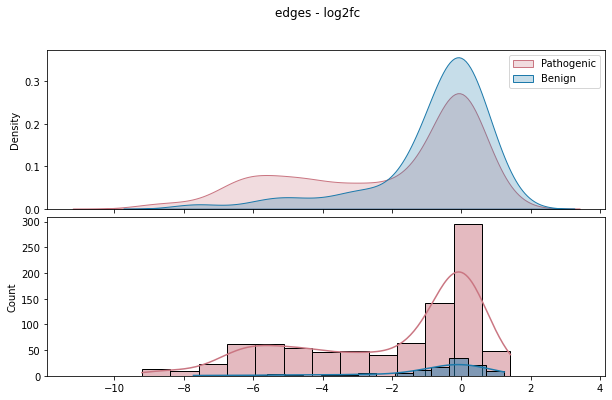

In [56]:
plot_patho_benign(scores=df, metric='log2fc', title=f"edges - log2fc")

# new LLR

In [ ]:
# OLD ONE FROM POOLED

def perturbation_LLR(df):
    df = df.copy()
    ASSUMED_PERTURBATION_SIZE = -5.0
    ASSUMED_PERTURBATION_DISTRIBUTION = 1.5
    ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.5
    ASSUMED_PERTURBATION_BOUND = -1.0

    # in the scipy API: loc is mean, scale is stddev
    loglikelihood_unperturbed_model = stats.norm.logpdf(
        df["log2FC_combined"],
        loc=0,
        scale=df["error_log2FC_combined"] + ASSUMED_NON_PERTURBATION_DISTRIBUTION,
    )

    log2fc = df["log2FC_combined"].to_numpy()
    error_log2fc = df["error_log2FC_combined"].to_numpy()

    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error_log2fc**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # Marginal (untruncated) distribution of y
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )

    # Posterior of theta | y under untruncated normal prior
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    # Probability that θ ≤ bound under this posterior
    log_post_cdf = stats.norm.logcdf(t)

    # Prior truncation normalising constant
    alpha = (
        ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE
    ) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)

    loglikelihood_perturbed_model = log_py + log_post_cdf - log_Z
    df["perturbation_LLR"] = (
        loglikelihood_unperturbed_model - loglikelihood_perturbed_model
    )
    return df

In [74]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import polars as pl

def perturbation_LLR_edge(df, default_error=0.5):
    """
    Calculates LLR for perturbation vs non-perturbation.
    Parameters tuned on 2025-12 dataset distributions:
      - Benign Width: ~0.9
      - Pathogenic Tail: ~ -4.5
    """
    # Convert Polars to Pandas if needed
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    
    df = df.copy()
    
    # 1. Handle Missing Error
    if "error_log2fc" not in df.columns:
        df["error_log2fc"] = default_error
        
    # 2. TUNED PARAMETERS
    ASSUMED_PERTURBATION_SIZE = -4.5              # Shifted from -5.0 to catch more signals
    ASSUMED_PERTURBATION_DISTRIBUTION = 2.0       # Widened from 1.5 to catch partial LOFs
    ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.8   # Widened from 0.5 to match Benign noise
    ASSUMED_PERTURBATION_BOUND = -1.5             # Anything > -1 is considered "WT-like" range
    
    # 3. Extract & Clean Data
    log2fc = df["log2fc"].to_numpy()
    # Check if error column has NaNs (e.g. from Polars nulls) and fill them
    error = df["error_log2fc"].fillna(default_error).to_numpy()
    
    # Safety floor for error
    error = np.maximum(error, 1e-3)

    # 4. Null Hypothesis (Unperturbed / WT-like)
    # Model: Normal(0, scale = Error + Intrinsic_WT_Width)
    scale_unperturbed = error + ASSUMED_NON_PERTURBATION_DISTRIBUTION
    loglikelihood_unperturbed = stats.norm.logpdf(
        log2fc, loc=0, scale=scale_unperturbed
    )
    
    # 5. Alt Hypothesis (Perturbed / LOF)
    # Model: Normal(Target, scale = Combined_Sigma)
    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )
    
    # Posterior Calculation (for Truncation)
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)
    
    loglikelihood_perturbed = log_py + log_post_cdf - log_Z
    
    # 6. Final Score
    # Positive = WT-like
    # Negative = Perturbed
    df["perturbation_LLR"] = loglikelihood_unperturbed - loglikelihood_perturbed
    
    return pl.from_pandas(df) # Return as Polars if preferred

<Axes: ylabel='Frequency'>

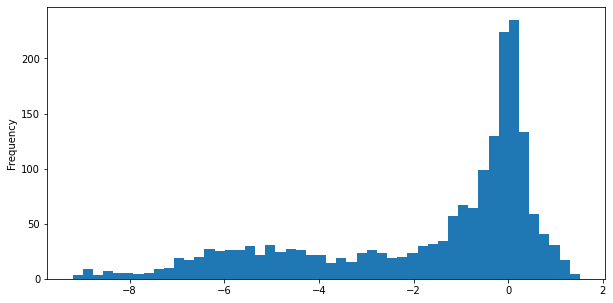

In [75]:
df.to_pandas().log2fc.plot.hist(bins=50, figsize=(10,5))

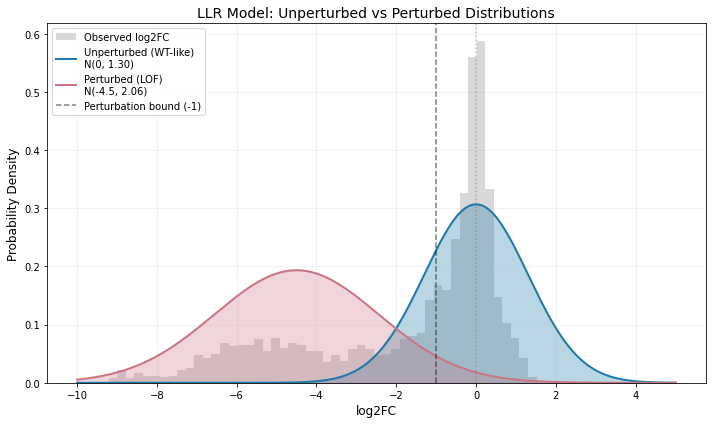

In [72]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Parameters from the function
ASSUMED_PERTURBATION_SIZE = -4.5
ASSUMED_PERTURBATION_DISTRIBUTION = 2.0
ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.8
default_error = 0.5

# Combined scale for each model
scale_unperturbed = default_error + ASSUMED_NON_PERTURBATION_DISTRIBUTION  # 1.3
scale_perturbed = np.sqrt(ASSUMED_PERTURBATION_DISTRIBUTION**2 + default_error**2)  # ~2.06

# X range for plotting
x = np.linspace(-10, 5, 500)

# PDFs
pdf_unperturbed = stats.norm.pdf(x, loc=0, scale=scale_unperturbed)
pdf_perturbed = stats.norm.pdf(x, loc=ASSUMED_PERTURBATION_SIZE, scale=scale_perturbed)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Plot actual data histogram (normalized to match PDF scale)
df.to_pandas()['log2fc'].plot.hist(bins=50, ax=ax, density=True, alpha=0.3, color='gray', label='Observed log2FC')

ax.plot(x, pdf_unperturbed, color="#1D7AAB", linewidth=2, label=f"Unperturbed (WT-like)\nN(0, {scale_unperturbed:.2f})")
ax.fill_between(x, pdf_unperturbed, alpha=0.3, color="#1D7AAB")

ax.plot(x, pdf_perturbed, color="#CA7682", linewidth=2, label=f"Perturbed (LOF)\nN({ASSUMED_PERTURBATION_SIZE}, {scale_perturbed:.2f})")
ax.fill_between(x, pdf_perturbed, alpha=0.3, color="#CA7682")

ax.axvline(x=-1, color='black', linestyle='--', alpha=0.5, label='Perturbation bound (-1)')
ax.axvline(x=0, color='gray', linestyle=':', alpha=0.5)

ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("Probability Density", fontsize=12)
ax.set_title("LLR Model: Unperturbed vs Perturbed Distributions", fontsize=14)
ax.legend(loc='upper left')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [76]:
df = perturbation_LLR_edge(df)

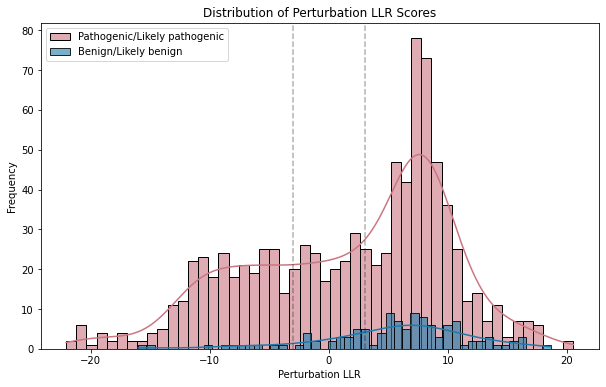

Pathogenic variants: 909
Benign variants: 116


In [77]:
# plot histogram of perturbation_LLR of pathogenic and benign variants
# Filter for pathogenic and benign variants
pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation LLR Scores")
plt.xlabel("Perturbation LLR")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=-3, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=3, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

In [79]:
df = df.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -3)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 3)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

In [80]:
def edgotype_status(status_list):
    status_list = status_list.to_list()
    if len(status_list) == 1:
        return np.nan
    if pd.isnull(status_list).all():
        return np.nan
    if 'perturbed' in status_list and 'unperturbed' in status_list:
        return 'edgetic'
    elif status_list.count('perturbed') >= 2:
        return 'quasi-null'
    elif status_list.count('unperturbed') >= 2:
        return 'quasi-wildtype'
    else:
        return 'uncertain'

# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

In [81]:
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
#   - edgotype confidence score
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    # 'cv_clinical_significance',
                    'clinvar_clnsig_clean',
                    # 'mondo_ids',
                    # 'blosum62',
                    # 'phyloP',
                    # 'allele_frequency',
                    # 'moi',
                    # 'am_pathogenicity',
                    # 'pLDDT',
                    # 'RSA',
                    # 'is_disordered',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')

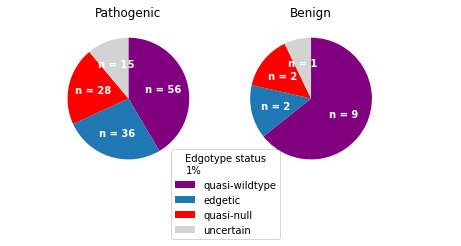

In [82]:
order = ['quasi-wildtype', 'edgetic', 'quasi-null', 'uncertain']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12))
for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order))
    vc.plot.pie(ax=ax,
                autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}",
                startangle=90,
                counterclock=False,
                colors=['purple', 'C0', 'red', 'lightgrey'],
                ylabel='',
                textprops={'color': 'white', 'weight': 'bold'},
                legend=True if cat == 'Pathogenic' else False,
                )
    ax.set_title(cat)
leg = axs[0].get_legend()
leg.set_title("Edgotype status\n1%")
leg.set_loc("upper left")
leg.set_bbox_to_anchor((0.75, 0.2))

In [83]:
edgotype[(edgotype.clinvar_clnsig_clean == 'Benign') & 
         (edgotype.edgotype_status == edgotype.edgotype_status)
         ]

,gene_variant,edgotype_status,n_ppi,n_measured_ppi,n_perturbed,n_unperturbed,n_uncertain,symbol,clinvar_clnsig_clean
8,ACSF3_Pro285Leu,quasi-null,3,3,3,0,0,ACSF3,Benign
65,BAG3_Arg258Trp,quasi-wildtype,10,10,0,9,1,BAG3,Benign
67,BAG3_Pro380Ser,quasi-wildtype,14,14,0,10,4,BAG3,Benign
123,GRN_Ser120Tyr,uncertain,7,7,0,1,6,GRN,Benign
124,GRN_Thr182Met,quasi-wildtype,7,7,0,6,1,GRN,Benign
196,KCNJ2_Ile258Thr,quasi-null,2,2,2,0,0,KCNJ2,Benign
242,KRT8_Gly434Ser,edgetic,5,5,1,2,2,KRT8,Benign
244,KRT8_Tyr54His,edgetic,5,5,1,4,0,KRT8,Benign
267,LITAF_Val81Met,quasi-wildtype,15,15,0,11,4,LITAF,Benign
275,MLH1_Lys751Arg,quasi-wildtype,17,17,0,17,0,MLH1,Benign


Log2FC at LLR = -3 (Perturbed):     -3.4501
Log2FC at LLR = 3  (Not Perturbed): -0.9579


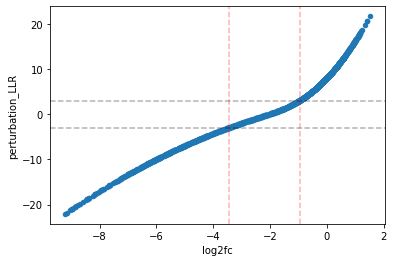

In [84]:
import numpy as np

# 1. Sort the data by LLR to ensure interpolation works correctly
df_sorted = df.sort_values('perturbation_LLR')

# 2. Use numpy.interp to solve for x (log2fc) given y (LLR)
# We swap x and y: np.interp(target_y, current_y, current_x)
cutoff_lower_log2fc = np.interp(-3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
cutoff_upper_log2fc = np.interp(3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])

print(f"Log2FC at LLR = -3 (Perturbed):     {cutoff_lower_log2fc:.4f}")
print(f"Log2FC at LLR = 3  (Not Perturbed): {cutoff_upper_log2fc:.4f}")

df.plot.scatter(x='log2fc', y='perturbation_LLR')
plt.axhline(y=-3, color='black', linestyle='--', alpha=0.3)
plt.axhline(y=3, color='black', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_lower_log2fc, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_upper_log2fc, color='red', linestyle='--', alpha=0.3)
plt.show()

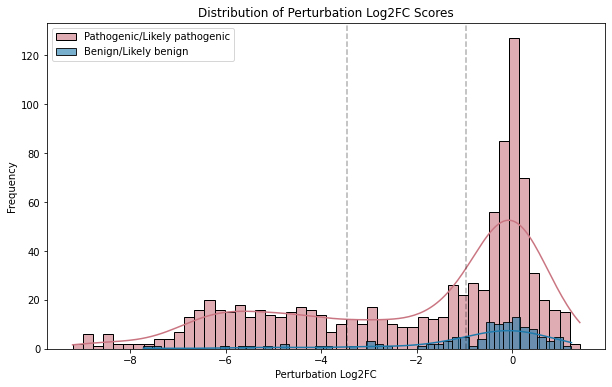

Pathogenic variants: 909
Benign variants: 116


In [85]:
# plot histogram of log2fc of pathogenic and benign variants
# Filter for pathogenic and benign variants

df = pl.DataFrame(df)

pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation Log2FC Scores")
plt.xlabel("Perturbation Log2FC")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=cutoff_lower_log2fc, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=cutoff_upper_log2fc, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

In [ ]:
df.columns

Index(['scoring_pla', 'scoring_pos', 'large_plate_name', 'retest_batch',
       'condition', 'condition_name', 'assay_id', 'media_control', 'ad_orf_id',
       'ad_mut_id', 'db_orf_id', 'db_mut_id', 'db_source_plate',
       'db_source_well', 'ad_source_plate', 'ad_source_well',
       'per_well_integrated_intensity_gray', 'manual_score_growth',
       'total_colony_area', 'Children_reExpandedColonies_Count', 'unique_id',
       'manual_score_growth_updated', 'contamination', 'outlier_score',
       'outlier_size_score', 'outlier_flag', 'size_score_raw', 'size_score',
       'ad_symbol', 'symbol', 'gene_variant', 'aa_change',
       'clinvar_clnsig_clean_pp_strict', 'splicing_variant', 'db_seq_final',
       'clinvar_clnsig_clean', 'db_group', 'db_condition_group', 'ppi_group',
       'edge_group', 'seq_ad', 'seq_db', 'db_seq_final_right',
       'manual_correction_applied', 'consensus_score', 'aa_score',
       'consensus_manual_score_growth', 'wt_consensus_score', 'log2fc',
       'p

In [ ]:
df[[
       'symbol', 'aa_change','ad_symbol',
       'clinvar_clnsig_clean', 'log2fc',
       'perturbation_LLR',
       'perturbation_status']].to_csv('./tmp/edge_df_LLR.csv', index=False)

# test space

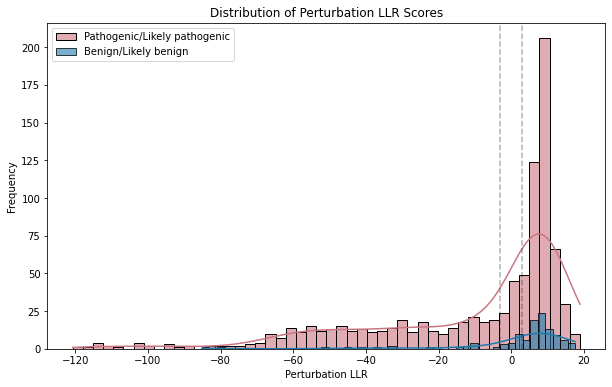

Pathogenic variants: 909
Benign variants: 116


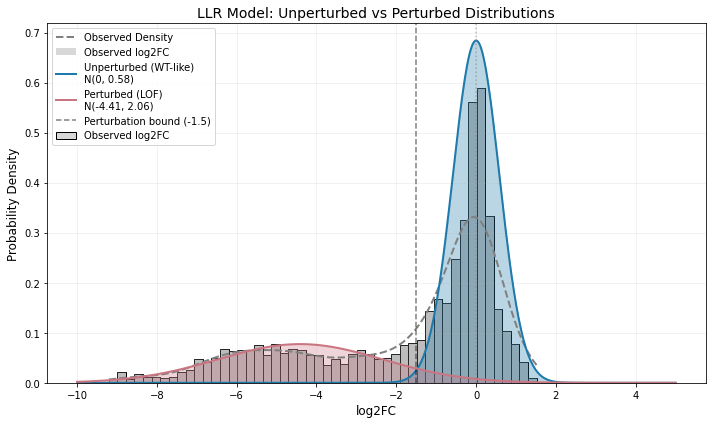

Log2FC at LLR = -3 (Perturbed):     -1.8635
Log2FC at LLR = 3  (Not Perturbed): -0.9021


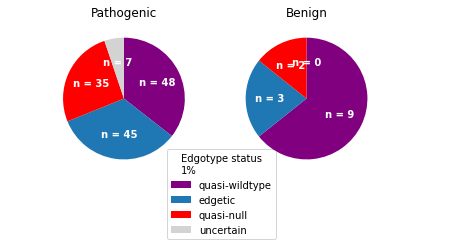

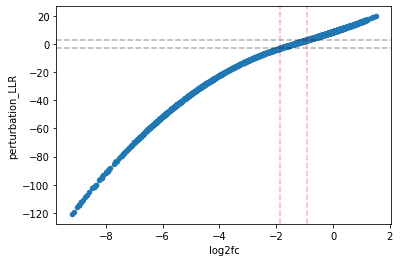

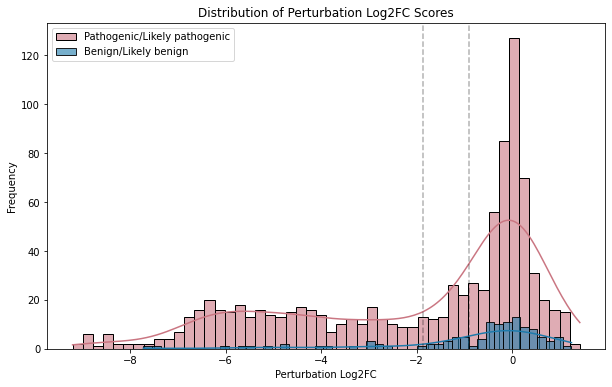

Pathogenic variants: 909
Benign variants: 116


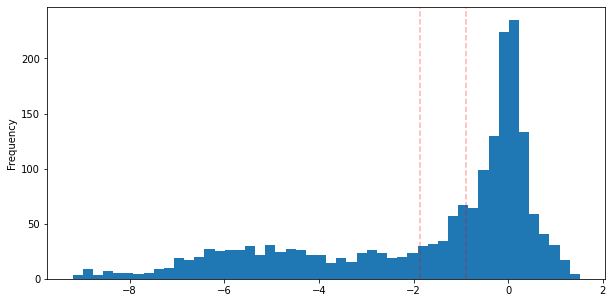

In [138]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import polars as pl

# 2. TUNED PARAMETERS
ASSUMED_PERTURBATION_SIZE = -4.41              
ASSUMED_PERTURBATION_DISTRIBUTION = 2      
ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.3   
ASSUMED_PERTURBATION_BOUND = -1.5

def perturbation_LLR_edge(df, default_error=0.5, ASSUMED_PERTURBATION_SIZE=ASSUMED_PERTURBATION_SIZE,
                          ASSUMED_PERTURBATION_DISTRIBUTION=ASSUMED_PERTURBATION_DISTRIBUTION,
                          ASSUMED_NON_PERTURBATION_DISTRIBUTION=ASSUMED_NON_PERTURBATION_DISTRIBUTION,
                          ASSUMED_PERTURBATION_BOUND=ASSUMED_PERTURBATION_BOUND):
    """
    Calculates LLR for perturbation vs non-perturbation.
    Parameters tuned on 2025-12 dataset distributions:
      - Benign Width: ~0.9
      - Pathogenic Tail: ~ -4.5
    """
    # Convert Polars to Pandas if needed
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
    
    df = df.copy()
    
    # 1. Handle Missing Error
    if "error_log2fc" not in df.columns:
        df["error_log2fc"] = default_error
        
    # # 2. TUNED PARAMETERS
    # ASSUMED_PERTURBATION_SIZE = -4.5              # Shifted from -5.0 to catch more signals
    # ASSUMED_PERTURBATION_DISTRIBUTION = 2.0       # Widened from 1.5 to catch partial LOFs
    # ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.8   # Widened from 0.5 to match Benign noise
    # ASSUMED_PERTURBATION_BOUND = -2             # Anything > -1 is considered "WT-like" range
    
    # 3. Extract & Clean Data
    log2fc = df["log2fc"].to_numpy()
    # Check if error column has NaNs (e.g. from Polars nulls) and fill them
    error = df["error_log2fc"].fillna(default_error).to_numpy()
    
    # Safety floor for error
    error = np.maximum(error, 1e-3)

    # 4. Null Hypothesis (Unperturbed / WT-like)
    # Model: Normal(0, scale = Error + Intrinsic_WT_Width)
    scale_unperturbed = np.sqrt(error**2 + ASSUMED_NON_PERTURBATION_DISTRIBUTION**2)
    loglikelihood_unperturbed = stats.norm.logpdf(
        log2fc, loc=0, scale=scale_unperturbed
    )
    
    # 5. Alt Hypothesis (Perturbed / LOF)
    # Model: Normal(Target, scale = Combined_Sigma)
    var_prior = ASSUMED_PERTURBATION_DISTRIBUTION**2
    var_measurement = error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    log_py = stats.norm.logpdf(
        log2fc, loc=ASSUMED_PERTURBATION_SIZE, scale=sigma_combined
    )
    
    # Posterior Calculation (for Truncation)
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (
        ASSUMED_PERTURBATION_SIZE / var_prior + log2fc / var_measurement
    )
    
    t = (ASSUMED_PERTURBATION_BOUND - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (ASSUMED_PERTURBATION_BOUND - ASSUMED_PERTURBATION_SIZE) / ASSUMED_PERTURBATION_DISTRIBUTION
    log_Z = stats.norm.logcdf(alpha)
    
    loglikelihood_perturbed = log_py + log_post_cdf - log_Z
    
    # 6. Final Score
    # Positive = WT-like
    # Negative = Perturbed
    df["perturbation_LLR"] = loglikelihood_unperturbed - loglikelihood_perturbed
    
    return pl.from_pandas(df) # Return as Polars if preferred


df = perturbation_LLR_edge(df)

# plot histogram of perturbation_LLR of pathogenic and benign variants
# Filter for pathogenic and benign variants
pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["perturbation_LLR"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation LLR Scores")
plt.xlabel("Perturbation LLR")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=-3, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=3, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# # Parameters from the function
# ASSUMED_PERTURBATION_SIZE = -4.5
# ASSUMED_PERTURBATION_DISTRIBUTION = 2.0
# ASSUMED_NON_PERTURBATION_DISTRIBUTION = 0.8
# ASSUMED_PERTURBATION_BOUND = -2
default_error = 0.5

# Combined scale for each model
scale_unperturbed = np.sqrt(default_error**2 + ASSUMED_NON_PERTURBATION_DISTRIBUTION**2)  # 1.3
scale_perturbed = np.sqrt(ASSUMED_PERTURBATION_DISTRIBUTION**2 + default_error**2)  # ~2.06

# X range for plotting
x = np.linspace(-10, 5, 500)

# PDFs
pdf_unperturbed = stats.norm.pdf(x, loc=0, scale=scale_unperturbed)
pdf_perturbed = stats.norm.pdf(x, loc=ASSUMED_PERTURBATION_SIZE, scale=scale_perturbed)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df.to_pandas(), 
    x='log2fc', 
    bins=50, 
    stat="density",      # Ensures it matches the scale of the PDF curves
    kde=True,            # <--- THIS ADDS THE DENSITY CURVE
    color='gray', 
    alpha=0.3, 
    label='Observed log2FC',
    ax=ax,
    line_kws={'linewidth': 2, 'linestyle': '--', 'label': 'Observed Density'} # Style the KDE line
)

# Plot actual data histogram (normalized to match PDF scale)
df.to_pandas()['log2fc'].plot.hist(bins=50, ax=ax, density=True, alpha=0.3, color='gray', label='Observed log2FC')

ax.plot(x, pdf_unperturbed, color="#1D7AAB", linewidth=2, label=f"Unperturbed (WT-like)\nN(0, {scale_unperturbed:.2f})")
ax.fill_between(x, pdf_unperturbed, alpha=0.3, color="#1D7AAB")

ax.plot(x, pdf_perturbed*0.4, color="#CA7682", linewidth=2, label=f"Perturbed (LOF)\nN({ASSUMED_PERTURBATION_SIZE}, {scale_perturbed:.2f})")
ax.fill_between(x, pdf_perturbed*0.4, alpha=0.3, color="#CA7682")

ax.axvline(x=ASSUMED_PERTURBATION_BOUND, color='black', linestyle='--', alpha=0.5, label=f'Perturbation bound ({ASSUMED_PERTURBATION_BOUND})')
ax.axvline(x=0, color='gray', linestyle=':', alpha=0.5)

ax.set_xlabel("log2FC", fontsize=12)
ax.set_ylabel("Probability Density", fontsize=12)
ax.set_title("LLR Model: Unperturbed vs Perturbed Distributions", fontsize=14)
ax.legend(loc='upper left')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

df = df.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -3)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 3)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

def edgotype_status(status_list):
    status_list = status_list.to_list()
    if len(status_list) == 1:
        return np.nan
    if pd.isnull(status_list).all():
        return np.nan
    if 'perturbed' in status_list and 'unperturbed' in status_list:
        return 'edgetic'
    elif status_list.count('perturbed') >= 2:
        return 'quasi-null'
    elif status_list.count('unperturbed') >= 2:
        return 'quasi-wildtype'
    else:
        return 'uncertain'

# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
#   - edgotype confidence score
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    # 'cv_clinical_significance',
                    'clinvar_clnsig_clean',
                    # 'mondo_ids',
                    # 'blosum62',
                    # 'phyloP',
                    # 'allele_frequency',
                    # 'moi',
                    # 'am_pathogenicity',
                    # 'pLDDT',
                    # 'RSA',
                    # 'is_disordered',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')


order = ['quasi-wildtype', 'edgetic', 'quasi-null', 'uncertain']

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12))
for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order))
    vc.plot.pie(ax=ax,
                autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}",
                startangle=90,
                counterclock=False,
                colors=['purple', 'C0', 'red', 'lightgrey'],
                ylabel='',
                textprops={'color': 'white', 'weight': 'bold'},
                legend=True if cat == 'Pathogenic' else False,
                )
    ax.set_title(cat)
leg = axs[0].get_legend()
leg.set_title("Edgotype status\n1%")
leg.set_loc("upper left")
leg.set_bbox_to_anchor((0.75, 0.2))

import numpy as np

# 1. Sort the data by LLR to ensure interpolation works correctly
df_sorted = df.sort_values('perturbation_LLR')

# 2. Use numpy.interp to solve for x (log2fc) given y (LLR)
# We swap x and y: np.interp(target_y, current_y, current_x)
cutoff_lower_log2fc = np.interp(-3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
cutoff_upper_log2fc = np.interp(3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])

print(f"Log2FC at LLR = -3 (Perturbed):     {cutoff_lower_log2fc:.4f}")
print(f"Log2FC at LLR = 3  (Not Perturbed): {cutoff_upper_log2fc:.4f}")

df.plot.scatter(x='log2fc', y='perturbation_LLR')
plt.axhline(y=-3, color='black', linestyle='--', alpha=0.3)
plt.axhline(y=3, color='black', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_lower_log2fc, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_upper_log2fc, color='red', linestyle='--', alpha=0.3)
plt.show()


# plot histogram of log2fc of pathogenic and benign variants
# Filter for pathogenic and benign variants

df = pl.DataFrame(df)

pathogenic_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
)
benign_df = df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
)

# Create figure
plt.figure(figsize=(10, 6))

# Plot histograms
sns.histplot(
    pathogenic_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#CA7682",
    label="Pathogenic/Likely pathogenic",
    alpha=0.6
)
sns.histplot(
    benign_df["log2fc"].to_numpy(), 
    bins=50, 
    kde=True, 
    color="#1D7AAB",
    label="Benign/Likely benign",
    alpha=0.6
)

plt.title("Distribution of Perturbation Log2FC Scores")
plt.xlabel("Perturbation Log2FC")
plt.ylabel("Frequency")
plt.legend()
plt.axvline(x=cutoff_lower_log2fc, color='black', linestyle='--', alpha=0.3, label='Low threshold')
plt.axvline(x=cutoff_upper_log2fc, color='black', linestyle='--', alpha=0.3, label='High threshold')
plt.show()

# Print summary statistics
print(f"Pathogenic variants: {pathogenic_df.shape[0]}")
print(f"Benign variants: {benign_df.shape[0]}")

df.to_pandas().log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_lower_log2fc, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_upper_log2fc, color='red', linestyle='--', alpha=0.3)
plt.show()

In [ ]:
# orf_distances = pl.read_csv(f'{outputs_dir}/orf_distances.csv', null_values=".", infer_schema_length=10000)
df = pl.read_csv(f'{outputs_dir}/edges_df.csv', null_values=".", infer_schema_length=10000)

# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

df = df.to_pandas()

df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
0,VUSAPWT6B1r04_022,G15,VUSAPWT6B1r04_019_020_021_022_023_024,VUSAPWT6B1,r16,LWH10,6,False,8447,None,...,1,1,Y,False,1.961140,0.000000,NaN,374.591178,-6.986866,PLP1_TMEM242_Leu189Pro
1,VUSAPWT1B1r03_031,E05,VUSAPWT1B1r03_031_032_033_034_035_036,VUSAPWT1B1,r09,LWH1,1,False,5441,None,...,1,1,Y,False,578.969135,19.826753,NaN,202.129272,1.513578,TH_PUF60_Gln39Glu
2,VUSAPWT1B1r04_017,E03,VUSAPWT1B1r04_013_014_015_016_017_018,VUSAPWT1B1,r10,LWH10,1,False,1863,None,...,1,1,Y,False,19.379852,0.016015,0.0,419.180453,-4.365794,LITAF_STAM2_Asn30Tyr
3,VUSAPWT6B1r05_007,C07,VUSAPWT6B1r05_007_008_009_010_011_012,VUSAPWT6B1,r17,LWH25,6,False,71963,None,...,1,1,Y,False,11.197526,15.663759,0.0,637.012269,-5.708924,MLH1_MBD3L1_Val185Gly
4,VUSAPWT1B1r04_015,G05,VUSAPWT1B1r04_013_014_015_016_017_018,VUSAPWT1B1,r10,LWH10,1,False,11132,None,...,1,1,Y,True,243.703549,NaN,2.0,467.899414,-0.938243,LITAF_EPN1_Ala129Val
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1858,VUSAPWT1B2r05_038,K15,VUSAPWT1B2r05_037_038_039_040_041_042,VUSAPWT1B2,r11,LWH25,1,False,100070143,None,...,1,1,Y,False,439.995931,0.437521,1.0,266.664224,0.720341,VHL_HSF2BP_His150Asp
1859,VUSAPWT1B2r05_020,M09,VUSAPWT1B2r05_019_020_021_022_023_024,VUSAPWT1B2,r11,LWH25,1,False,1586,None,...,1,1,Y,False,473.988686,5.231145,3.0,274.271497,0.787038,NAA10_KIFAP3_Arg116Trp
1860,VUSAPWT1B2r05_022,A23,VUSAPWT1B2r05_019_020_021_022_023_024,VUSAPWT1B2,r11,LWH25,1,False,2098,None,...,1,1,Y,False,565.985273,18.550897,3.0,340.280087,0.732355,KCTD7_EFHC2_Arg94Trp
1861,VUSAPWT1B2r05_027,K01,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,100067112,None,...,1,1,Y,True,5.935809,127.712100,0.0,604.497710,-6.447914,PCCA_MCC_Met348Lys


# Manual optimizer and classifier

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.6715
Mutant Intrinsic Sig: 2.4111
Measurement Error:    0.5622
Bound (Fixed):        -1.5000


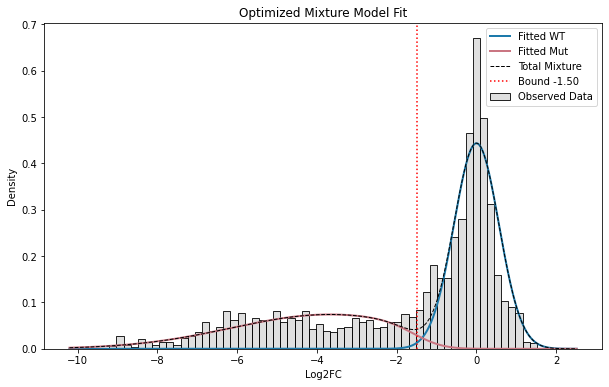


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -0.7633
Log2FC at LLR < -3 (Mutant): -1.7563


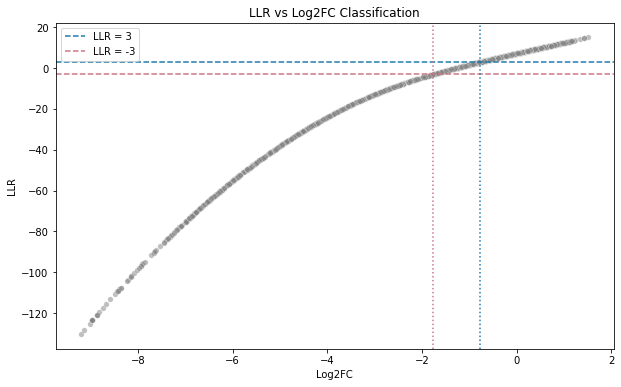

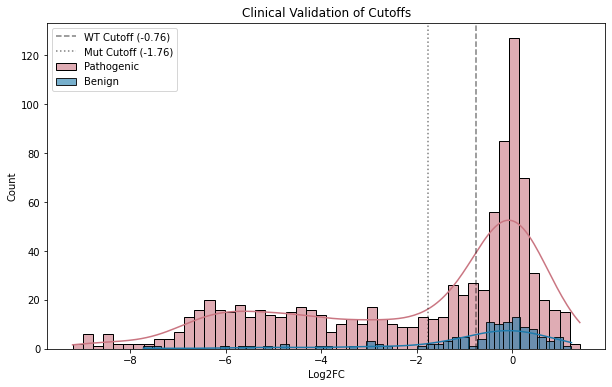

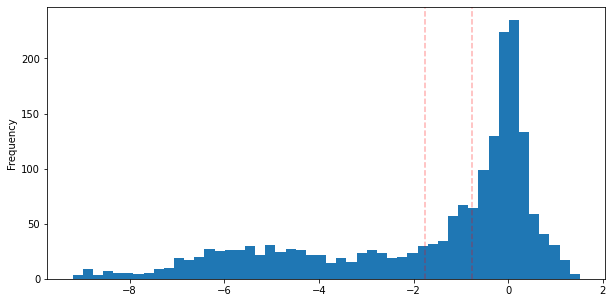

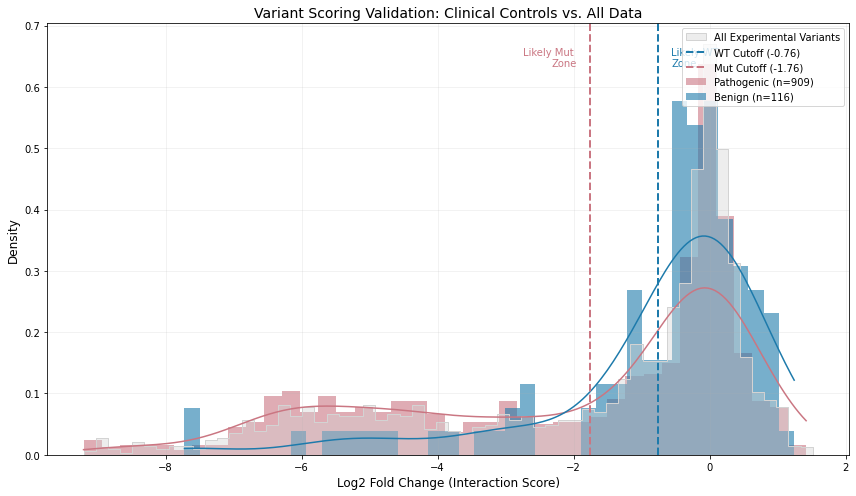

In [274]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
FIXED_BOUND = -1.5 # Hard biological limit

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def get_convolved_pdf(x_data, mu, sigma_bio, bound, sigma_error):
    """
    Computes the PDF of a Truncated Normal (intrinsic) convolved with Normal (noise).
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated distribution (Prior + Noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters for the Truncation Term
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Truncation Adjustment Terms
    t = (bound - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (bound - mu) / sigma_bio
    log_Z = stats.norm.logcdf(alpha)
    
    # Final Log PDF
    log_result = log_py + log_post_cdf - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf(log2fc_values, mu_mut, sigma_mut, FIXED_BOUND, sigma_error)
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 2.0, 0.2, 0.5]

bounds = [
    (0.01, 1.0),    # sigma_wt
    (-12.0, -2.0),  # mu_mut
    # (-5, -5),  # mu_mut
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {FIXED_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(min(log2fc_values)-1, max(log2fc_values)+1, 1000)

# WT Curve
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=sigma_total_wt)

# Mut Curve
y_mut_raw = get_convolved_pdf(x_plot, opt_mu_mut, opt_sigma_mut, FIXED_BOUND, opt_sigma_error)
y_mut = opt_w_mut * y_mut_raw

# Total
y_total = y_wt + y_mut

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1, label='Total Mixture')
plt.axvline(FIXED_BOUND, color='red', linestyle=':', label=f'Bound {FIXED_BOUND:.2f}')

plt.title("Optimized Mixture Model Fit")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, sigma_wt, bound, sigma_error):
    """
    Calculates LLR using the consistent optimized parameters.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
        
    row_error = np.maximum(row_error, 1e-3) # Safety floor

    # --- Null Hypothesis (WT) ---
    # Model: Normal(0, scale = sqrt(Error^2 + Intrinsic_WT^2))
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)
    
    # --- Alt Hypothesis (Mutant) ---
    # Model: Convolved Truncated Normal
    pdt_mut = get_convolved_pdf(log2fc, mu_mut, sigma_mut, bound, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))  # Safety floor
    
    # --- Final Score ---
    # LLR = Log(P(WT)) - Log(P(Mut))
    # Positive = WT, Negative = Mutant
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df, 
    mu_mut=opt_mu_mut, 
    sigma_mut=opt_sigma_mut, 
    sigma_wt=opt_sigma_wt, 
    bound=FIXED_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


plt.figure(figsize=(12, 7))



# 2. Foreground: Pathogenic Variants
sns.histplot(
    pathogenic_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#CA7682", 
    label=f"Pathogenic (n={len(pathogenic_df)})", 
    alpha=0.6,
    edgecolor=None # Removes bar edges for cleaner look on top of grey
)

# 3. Foreground: Benign Variants
sns.histplot(
    benign_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#1D7AAB", 
    label=f"Benign (n={len(benign_df)})", 
    alpha=0.6,
    edgecolor=None
)

# 1. Background: Full Dataset (Context)
# We use 'density' so it can be compared with the smaller clinical subsets
sns.histplot(
    log2fc_values, 
    stat='density', 
    bins=60, 
    color='lightgrey', 
    alpha=0.4, 
    label='All Experimental Variants',
    element="step",  # 'step' makes the outline cleaner for the background
    fill=True
)

# 4. Cutoff Lines
plt.axvline(x=cutoff_wt, color='#1D7AAB', linestyle='--', linewidth=2, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='#CA7682', linestyle='--', linewidth=2, label=f'Mut Cutoff ({cutoff_mut:.2f})')

# Annotations (Optional but helpful)
plt.text(cutoff_wt + 0.2, plt.ylim()[1]*0.9, "Likely WT \nZone", color='#1D7AAB', ha='left')
plt.text(cutoff_mut - 0.2, plt.ylim()[1]*0.9, "Likely Mut \nZone", color='#CA7682', ha='right')

plt.title("Variant Scoring Validation: Clinical Controls vs. All Data", fontsize=14)
plt.xlabel("Log2 Fold Change (Interaction Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Chatgpt implementation of two trunc

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.4410
Mutant Intrinsic Sig: 2.6591
Measurement Error:    0.5575
Bound (Fixed):        -1.5000


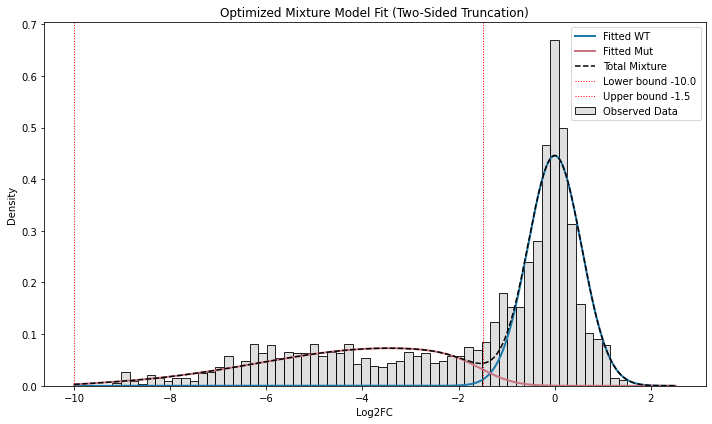


=== CUTOFFS ===
Log2FC at LLR > 3 (WT):      -0.7504
Log2FC at LLR < -3 (Mutant): -1.7356


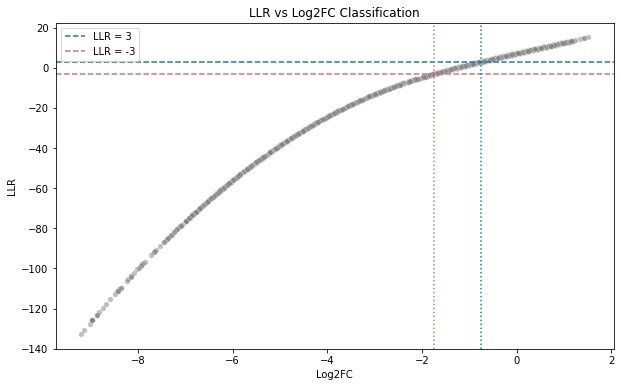

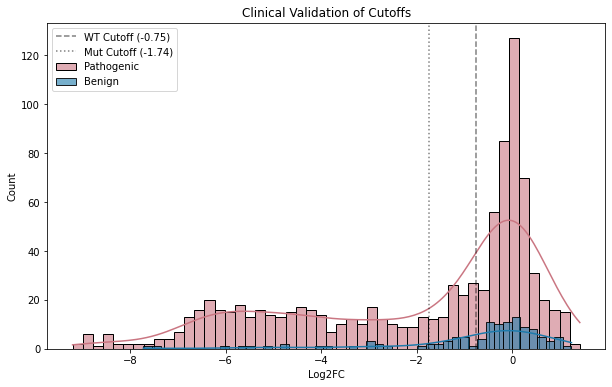

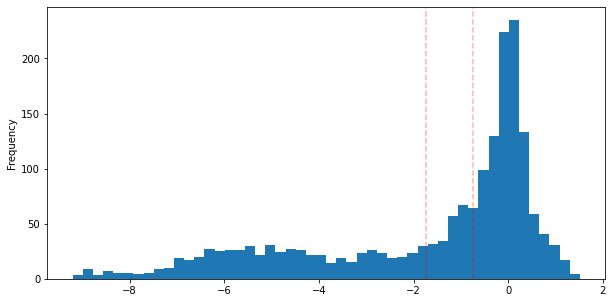

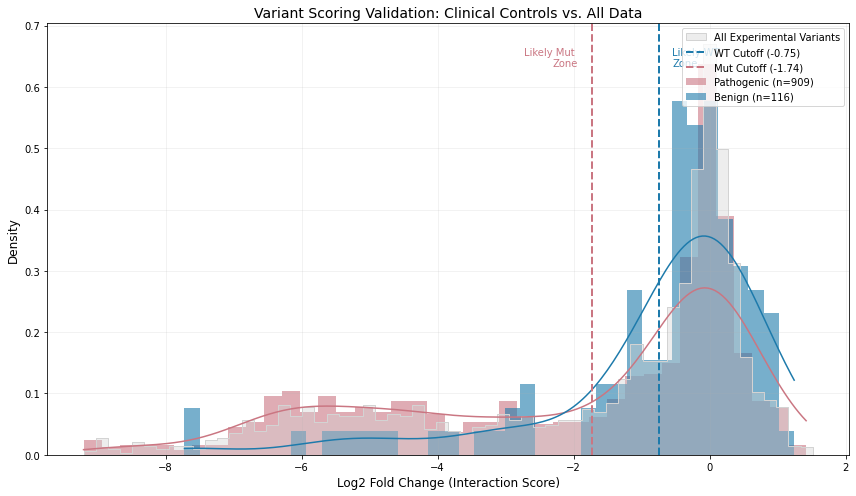

In [280]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
RIGHT_BOUND = -1.5 # Hard biological limit
LEFT_BOUND = -10.0 # For numerical stability in truncation

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def _logdiffexp(a, b):
    """log(exp(a) - exp(b)) stable, assumes a > b."""
    return a + np.log1p(-np.exp(b - a))

def get_convolved_pdf_two_sided(x_data, mu, sigma_bio, lower, upper, sigma_error):
    """
    PDF of (Truncated Normal intrinsic on [lower, upper]) convolved with Normal noise.
    This generalizes your one-sided formula to two-sided truncation.
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)

    # A) Untruncated (prior + noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)

    # B) Posterior params used in truncation factor
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)

    # C) Two-sided truncation adjustment using posterior CDF window
    t_hi = (upper - mu_post) / sigma_post
    t_lo = (lower - mu_post) / sigma_post

    # log(Φ(t_hi) - Φ(t_lo)) stably
    logPhi_hi = stats.norm.logcdf(t_hi)
    logPhi_lo = stats.norm.logcdf(t_lo)

    # ensure hi >= lo numerically
    log_post_window = np.where(
        t_hi > t_lo,
        _logdiffexp(logPhi_hi, logPhi_lo),
        -np.inf
    )

    # D) Prior normalization over [lower, upper]
    a_hi = (upper - mu) / sigma_bio
    a_lo = (lower - mu) / sigma_bio
    logZ_hi = stats.norm.logcdf(a_hi)
    logZ_lo = stats.norm.logcdf(a_lo)

    log_Z = _logdiffexp(logZ_hi, logZ_lo)

    # Final log pdf
    log_result = log_py + log_post_window - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf_two_sided(
    log2fc_values, mu_mut, sigma_mut,
    LEFT_BOUND, RIGHT_BOUND,
    sigma_error
)

    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 2.0, 0.2, 0.5]

bounds = [
    (0.01, 1.0),    # sigma_wt
    (-10.0, -2.0),  # mu_mut
    # (-5, -5),  # mu_mut
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {RIGHT_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================

plt.figure(figsize=(10, 6))
sns.histplot(
    log2fc_values,
    stat='density',
    bins=60,
    color='silver',
    alpha=0.5,
    label='Observed Data'
)

# Plot range must include full truncation support
x_plot = np.linspace(LEFT_BOUND, max(log2fc_values) + 1, 2000)

# --- WT Curve (unchanged) ---
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(
    x_plot, loc=0, scale=sigma_total_wt
)

# --- Mutant Curve (two-sided truncated convolution) ---
y_mut_raw = get_convolved_pdf_two_sided(
    x_plot,
    opt_mu_mut,
    opt_sigma_mut,
    LEFT_BOUND,
    RIGHT_BOUND,
    opt_sigma_error
)
y_mut = opt_w_mut * y_mut_raw

# --- Total mixture ---
y_total = y_wt + y_mut

# --- Plot ---
plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1.5, label='Total Mixture')

# Truncation bounds
plt.axvline(LEFT_BOUND, color='red', linestyle=':', lw=1, label=f'Lower bound {LEFT_BOUND}')
plt.axvline(RIGHT_BOUND, color='red', linestyle=':', lw=1, label=f'Upper bound {RIGHT_BOUND}')

plt.title("Optimized Mixture Model Fit (Two-Sided Truncation)")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, sigma_wt, lower_bound, upper_bound, sigma_error):
    """
    Calculates LLR using consistent optimized parameters.
    LLR = log p(x | WT) - log p(x | Mut)
    Mutant model: truncated intrinsic Normal on [lower_bound, upper_bound] convolved with Normal error.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()

    log2fc = df_out["log2fc"].to_numpy()

    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)

    row_error = np.maximum(row_error, 1e-3)  # Safety floor

    # --- Null Hypothesis (WT) ---
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)

    # --- Alt Hypothesis (Mutant) ---
    p_mut = get_convolved_pdf_two_sided(
        log2fc,
        mu_mut,
        sigma_mut,
        lower_bound,
        upper_bound,
        row_error
    )
    loglik_mut = np.log(np.maximum(p_mut, 1e-100))  # Safety floor

    # --- Final Score ---
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut

    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df,
    mu_mut=opt_mu_mut,
    sigma_mut=opt_sigma_mut,
    sigma_wt=opt_sigma_wt,
    lower_bound=LEFT_BOUND,
    upper_bound=RIGHT_BOUND,
    sigma_error=opt_sigma_error
)

df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(3, y_vals, x_vals)
cutoff_mut = np.interp(-3, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 3 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -3 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()


plt.figure(figsize=(12, 7))



# 2. Foreground: Pathogenic Variants
sns.histplot(
    pathogenic_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#CA7682", 
    label=f"Pathogenic (n={len(pathogenic_df)})", 
    alpha=0.6,
    edgecolor=None # Removes bar edges for cleaner look on top of grey
)

# 3. Foreground: Benign Variants
sns.histplot(
    benign_df["log2fc"], 
    stat='density',
    bins=40, 
    kde=True, 
    color="#1D7AAB", 
    label=f"Benign (n={len(benign_df)})", 
    alpha=0.6,
    edgecolor=None
)

# 1. Background: Full Dataset (Context)
# We use 'density' so it can be compared with the smaller clinical subsets
sns.histplot(
    log2fc_values, 
    stat='density', 
    bins=60, 
    color='lightgrey', 
    alpha=0.4, 
    label='All Experimental Variants',
    element="step",  # 'step' makes the outline cleaner for the background
    fill=True
)

# 4. Cutoff Lines
plt.axvline(x=cutoff_wt, color='#1D7AAB', linestyle='--', linewidth=2, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='#CA7682', linestyle='--', linewidth=2, label=f'Mut Cutoff ({cutoff_mut:.2f})')

# Annotations (Optional but helpful)
plt.text(cutoff_wt + 0.2, plt.ylim()[1]*0.9, "Likely WT \nZone", color='#1D7AAB', ha='left')
plt.text(cutoff_mut - 0.2, plt.ylim()[1]*0.9, "Likely Mut \nZone", color='#CA7682', ha='right')

plt.title("Variant Scoring Validation: Clinical Controls vs. All Data", fontsize=14)
plt.xlabel("Log2 Fold Change (Interaction Score)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Gemini implementation of two trunc

Optimizing with bounds: [-10.0, -1.5]...

=== OPTIMIZED PARAMETERS ===
WT Intrinsic Sigma:   0.0100
Mutant Mean:          -3.4410
Mutant Intrinsic Sig: 2.6590
Measurement Error:    0.5575
Bounds:               [-10.0, -1.5]


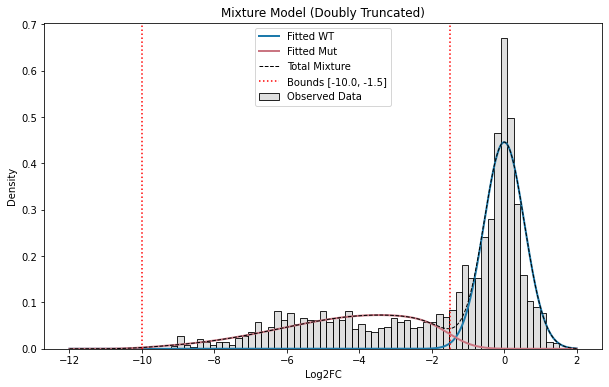


WT Cutoff (LLR > 3): -0.750
Mut Cutoff (LLR < -3): -1.736


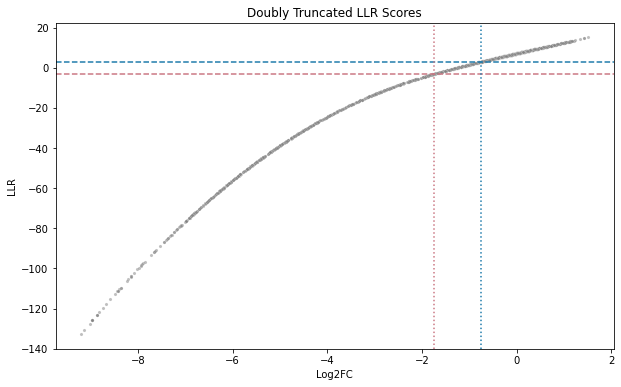

In [275]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
# Ensure df is available in your environment
if isinstance(df, pl.DataFrame):
    log2fc_values = df['log2fc'].drop_nulls().to_numpy()
else:
    log2fc_values = df['log2fc'].dropna().to_numpy()

# DEFINING BOUNDS
UPPER_BOUND = -1.5  # Hard biological limit (upper)
LOWER_BOUND = -10.0 # Hard biological limit (lower - detection limit)

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def log_diff_cdf(upper_z, lower_z):
    """
    Computes log(CDF(upper) - CDF(lower)) safely.
    Uses log-space arithmetic to prevent underflow.
    """
    # log_cdf_upper = log(P(Z < upper))
    # log_cdf_lower = log(P(Z < lower))
    # We want log(exp(log_cdf_upper) - exp(log_cdf_lower))
    
    log_u = stats.norm.logcdf(upper_z)
    log_l = stats.norm.logcdf(lower_z)
    
    # Use numpy's logaddexp to handle the subtraction safely in log space:
    # log(A - B) = log(A) + log(1 - exp(log(B) - log(A)))
    # Note: This assumes upper_z > lower_z. If not, return -inf.
    
    mask = (log_u > log_l)
    
    # Safe computation for valid ranges
    # We use a small epsilon for stability if needed, but direct formula usually works
    val = log_u + np.log1p(-np.exp(log_l - log_u))
    
    # If the interval is effectively zero or inverted, return extremely low log prob
    return np.where(mask, val, -np.inf)

def get_doubly_convolved_pdf(x_data, mu, sigma_bio, lower_b, upper_b, sigma_error):
    """
    Computes the PDF of a Doubly Truncated Normal (intrinsic) convolved with Normal (noise).
    
    P(y) = N(y | mu, sqrt(sigma_bio^2 + sigma_err^2)) * [Mass_Post / Mass_Prior]
    
    Where:
    - Mass_Prior: P(lower < X < upper) for the intrinsic distribution
    - Mass_Post:  P(lower < X < upper) for the posterior distribution P(x|y)
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated Marginal Likelihood (The "Infinite" Case)
    log_py_unbounded = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters (Where is the true value likely to be, given observed y?)
    #    New Mean = Weighted average of Prior Mean and Observed Data
    #    New Var  = Harmonic sum of variances
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Calculate Normalization Terms (Mass within bounds)
    
    # 1. Posterior Mass: Proportion of the posterior belief that falls inside [lower, upper]
    z_post_upper = (upper_b - mu_post) / sigma_post
    z_post_lower = (lower_b - mu_post) / sigma_post
    log_mass_post = log_diff_cdf(z_post_upper, z_post_lower)
    
    # 2. Prior Mass: Proportion of the original biological distribution inside [lower, upper]
    #    This is a constant scalar for given parameters, but calculated vectorized for safety
    z_prior_upper = (upper_b - mu) / sigma_bio
    z_prior_lower = (lower_b - mu) / sigma_bio
    log_mass_prior = log_diff_cdf(z_prior_upper, z_prior_lower)
    
    # D. Final Log PDF
    # log(P(y)) = log(P_unbounded) + log(Mass_Post) - log(Mass_Prior)
    log_result = log_py_unbounded + log_mass_post - log_mass_prior
    
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization with Double Truncation.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error = params
    
    # Constraints / Safety checks
    if sigma_wt < 0.01 or sigma_mut < 0.01 or w_mut < 0.01 or w_mut > 0.99 or sigma_error < 0.01:
        return np.inf
    
    # --- WT COMPONENT (Standard Normal) ---
    sigma_total_wt = np.sqrt(sigma_wt**2 + sigma_error**2)
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_total_wt)
    
    # --- MUTANT COMPONENT (Doubly Truncated Convolution) ---
    pdf_mut = get_doubly_convolved_pdf(
        log2fc_values, 
        mu_mut, 
        sigma_mut, 
        LOWER_BOUND, 
        UPPER_BOUND, 
        sigma_error
    )
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error
initial_guess = [0.3, -6.0, 3.0, 0.2, 0.5]

bounds = [
    (0.01, 1.5),    # sigma_wt
    (-9.0, -3.0),   # mu_mut (Constrained slightly inside the bounds for stability)
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 2.0)     # sigma_error
]

print(f"Optimizing with bounds: [{LOWER_BOUND}, {UPPER_BOUND}]...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

opt_sigma_wt, opt_mu_mut, opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"WT Intrinsic Sigma:   {opt_sigma_wt:.4f}")
print(f"Mutant Mean:          {opt_mu_mut:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bounds:               [{LOWER_BOUND}, {UPPER_BOUND}]")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(LOWER_BOUND - 2, 2, 1000)

# WT Curve
sigma_total_wt = np.sqrt(opt_sigma_wt**2 + opt_sigma_error**2)
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=sigma_total_wt)

# Mut Curve
y_mut_raw = get_doubly_convolved_pdf(
    x_plot, 
    opt_mu_mut, 
    opt_sigma_mut, 
    LOWER_BOUND, 
    UPPER_BOUND, 
    opt_sigma_error
)
y_mut = opt_w_mut * y_mut_raw

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_wt + y_mut, color='black', linestyle='--', lw=1, label='Total Mixture')

# Draw Bounds
plt.axvline(UPPER_BOUND, color='red', linestyle=':', label=f'Bounds [{LOWER_BOUND}, {UPPER_BOUND}]')
plt.axvline(LOWER_BOUND, color='red', linestyle=':')

plt.title("Mixture Model (Doubly Truncated)")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr_doubly_truncated(df_in, mu_mut, sigma_mut, sigma_wt, lower_b, upper_b, sigma_error):
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
    row_error = np.maximum(row_error, 1e-3)

    # --- Null Hypothesis (WT) ---
    scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=scale_wt)
    
    # --- Alt Hypothesis (Mutant) ---
    pdt_mut = get_doubly_convolved_pdf(log2fc, mu_mut, sigma_mut, lower_b, upper_b, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))
    
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

df_result_pl = compute_perturbation_llr_doubly_truncated(
    df, 
    mu_mut=opt_mu_mut, 
    sigma_mut=opt_sigma_mut, 
    sigma_wt=opt_sigma_wt, 
    lower_b=LOWER_BOUND,
    upper_b=UPPER_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & PLOT
# ==========================================
# Sort strictly by LLR for clean interpolation
df_sorted = df_result.sort_values('perturbation_LLR')

# Filter for interpolation range to avoid errors if LLR doesn't reach +/-3
if df_sorted['perturbation_LLR'].min() < -3 and df_sorted['perturbation_LLR'].max() > 3:
    cutoff_wt = np.interp(3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
    cutoff_mut = np.interp(-3, df_sorted['perturbation_LLR'], df_sorted['log2fc'])
    print(f"\nWT Cutoff (LLR > 3): {cutoff_wt:.3f}")
    print(f"Mut Cutoff (LLR < -3): {cutoff_mut:.3f}")
else:
    print("\nWarning: LLR scores did not reach +/- 3 threshold.")
    cutoff_wt, cutoff_mut = 0, -3 # Fallback defaults

# Final LLR Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=10)
plt.axhline(3, color='#1D7AAB', ls='--')
plt.axhline(-3, color='#CA7682', ls='--')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("Doubly Truncated LLR Scores")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.show()